In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
from scipy.special import erfcinv
import random
import seaborn as sns
from scipy.stats import norm

In [3]:
%%time
# the brute force way
mu  = 1
sigma = 1.0
N = 10000 #sample size
p = 1000 #number of independent draws of the sample size
total_pop = np.random.normal(mu, sigma, N*p)
total_pop = np.reshape(total_pop,(p,N))
total_pop.shape
maxima = np.max(total_pop, axis = 1)
# maxima

CPU times: user 105 ms, sys: 36.6 ms, total: 142 ms
Wall time: 148 ms


In [4]:
%%time

# Cleaner equivalent — handles mu and sigma directly
maxima_curs = norm.ppf(np.random.rand(p)**(1/N), loc=mu, scale=sigma)

CPU times: user 6.85 ms, sys: 64 μs, total: 6.92 ms
Wall time: 6.47 ms


In [5]:
%%time
# the extreme value way
draw = np.random.rand(p)**(1/N)
max2 = np.sqrt(2)*sigma*erfcinv(2*(1-draw)) + mu
# max2

CPU times: user 672 μs, sys: 64 μs, total: 736 μs
Wall time: 663 μs


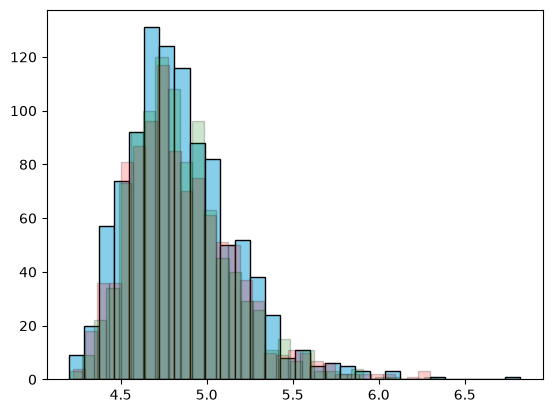

In [6]:
plt.hist(max2, bins=30, edgecolor='black', color='skyblue')
plt.hist(maxima, bins=30, edgecolor='black', color='red',alpha = 0.2)
plt.hist(maxima_curs, bins=30, edgecolor='black', color='green',alpha = 0.2)
plt.show()

## How to combine extremas from two diffrent normal processes

In [13]:
p = int(1E3)
N = int(1E4)

np.random.seed(21)
sigma1  = 3.4
pop_base_1 = np.random.normal(0, sigma1, N*p)

np.random.seed(22)
sigma2  = 1.4
pop_base_2 = np.random.normal(0, sigma2, N*p)

comb_pop = pop_base_1 + pop_base_2
comb_pop = np.reshape(comb_pop,(p,N))
maxima_bf = np.max(comb_pop, axis = 1)

# two ways of combining EV
np.random.seed(2)
draw = np.random.rand(p)**(1/N)
sigma = np.sqrt(sigma1**2.0 + sigma2**2.0)
max_pre_RSS = np.sqrt(2)*sigma*erfcinv(2*(1-draw))

np.random.seed(42)
draw = np.random.rand(p)**(1/N)
max1 = np.sqrt(2)*sigma1*erfcinv(2*(1-draw))

np.random.seed(42)
draw = np.random.rand(p)**(1/N)
max2 = np.sqrt(2)*sigma2*erfcinv(2*(1-draw))

max_post_RSS = np.sqrt(max1**2.0 + max2**2.0)

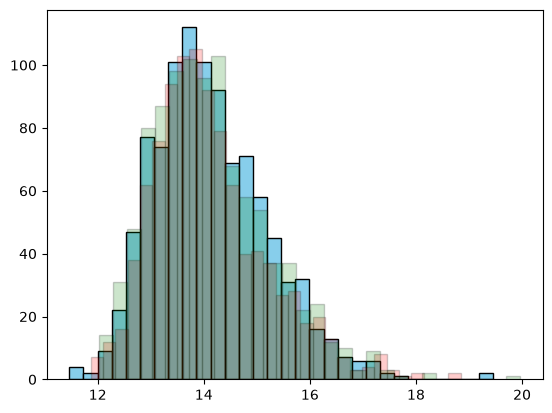

In [14]:
plt.hist(maxima_bf, bins=30, edgecolor='black', color='skyblue')
plt.hist(max_pre_RSS, bins=30, edgecolor='black', color='red',alpha = 0.2)
plt.hist(max_post_RSS, bins=30, edgecolor='black', color='green',alpha = 0.2)
plt.show()